# 05 · Splitting and class imbalance

**Why.** An honest evaluation: one shared 80/20 split, a test set nobody touches until the very end, all preprocessing inside the model pipelines, and evidence (not assumptions) about class weighting and repeated answer profiles.

**Re-run it** (gives byte-identical split files):

```bash
diabetes-screening-model split --input data/derived/combined_BRFSS2015.csv \
  --provenance data/derived/combined_BRFSS2015.provenance.json --output outputs/combined/split
diabetes-screening-model imbalance --input data/derived/combined_BRFSS2015.csv \
  --provenance data/derived/combined_BRFSS2015.provenance.json \
  --split outputs/combined/split --output outputs/combined/imbalance
```

In [1]:
# Every notebook reads the committed aggregate reports, so it runs from a fresh clone without the survey data.
from pathlib import Path
import json

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
ENDPOINT = "combined"  # "prediabetes" shows the sensitivity analysis instead
REPORTS = ROOT / "reports"
STAGE_1_4 = REPORTS / ("uploaded-combined" if ENDPOINT == "combined" else "prediabetes")
MODELING = REPORTS / "modeling" / ENDPOINT
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 100)


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def figure(path, width=860):
    display(Image(filename=str(path), width=width))

In [2]:
split = read_json(MODELING / "split" / "split.json")
sides = pd.DataFrame({side: split[side] for side in ["train", "test"]}).T
sides["rows"], sides["positives"] = sides["rows"].astype(int), sides["positives"].astype(int)
print(f"Strategy: {split['strategy']}, seed {split['seed']}, {split['n_splits']} folds; "
      f"assignment hash {split['assignment_sha256'][:12]}")
sides

Strategy: stratified, seed 42, 5 folds; assignment hash e8a579495ac8


,rows,positives,prevalence
train,202944,31982,0.158
test,50736,7995,0.158


In [3]:
pd.DataFrame(split["folds"]).set_index("fold")

,rows,positives,prevalence
fold,,,
0,40589,6396,0.158
1,40589,6396,0.158
2,40589,6397,0.158
3,40589,6397,0.158
4,40588,6396,0.158


## Do people with identical answers leak information?

About 15% of respondents share their exact answers with someone else. If that let models "recognise" people, folds that keep identical profiles together would score clearly lower.

In [4]:
profiles = read_json(MODELING / "split" / "profiles.json")
print(f"{profiles['share_of_rows_in_repeated_profiles']:.1%} of rows are in repeated profiles; "
      f"{profiles['repeated_profiles_with_both_outcomes']:,} repeated profiles include both outcomes")
pd.read_csv(MODELING / "imbalance" / "grouped_cv_check.csv")[["model", "cv_folds", "pr_auc_mean", "pr_auc_drop_vs_plain"]]

15.0% of rows are in repeated profiles; 1,804 repeated profiles include both outcomes


,model,cv_folds,pr_auc_mean,pr_auc_drop_vs_plain
0,logistic_regression,plain stratified,0.431,0.000e+00
1,logistic_regression,profile-grouped,0.431,7.176e-05
2,random_forest,plain stratified,0.456,0.000e+00
3,random_forest,profile-grouped,0.455,9.549e-04
4,xgboost,plain stratified,0.458,0.000e+00
5,xgboost,profile-grouped,0.458,9.349e-05


## Does class weighting help?

In [5]:
weighting = pd.read_csv(MODELING / "imbalance" / "weighting_summary.csv")
weighting[["model", "weighting", "pr_auc_mean", "roc_auc_mean", "brier_mean", "mean_predicted_risk_mean"]]

,model,weighting,pr_auc_mean,roc_auc_mean,brier_mean,mean_predicted_risk_mean
0,logistic_regression,unweighted,0.431,0.817,0.109,0.158
1,logistic_regression,weighted,0.430,0.818,0.179,0.395
2,random_forest,unweighted,0.456,0.822,0.106,0.158
3,random_forest,weighted,0.455,0.823,0.172,0.386
4,xgboost,unweighted,0.458,0.825,0.106,0.157
5,xgboost,weighted,0.459,0.825,0.176,0.385


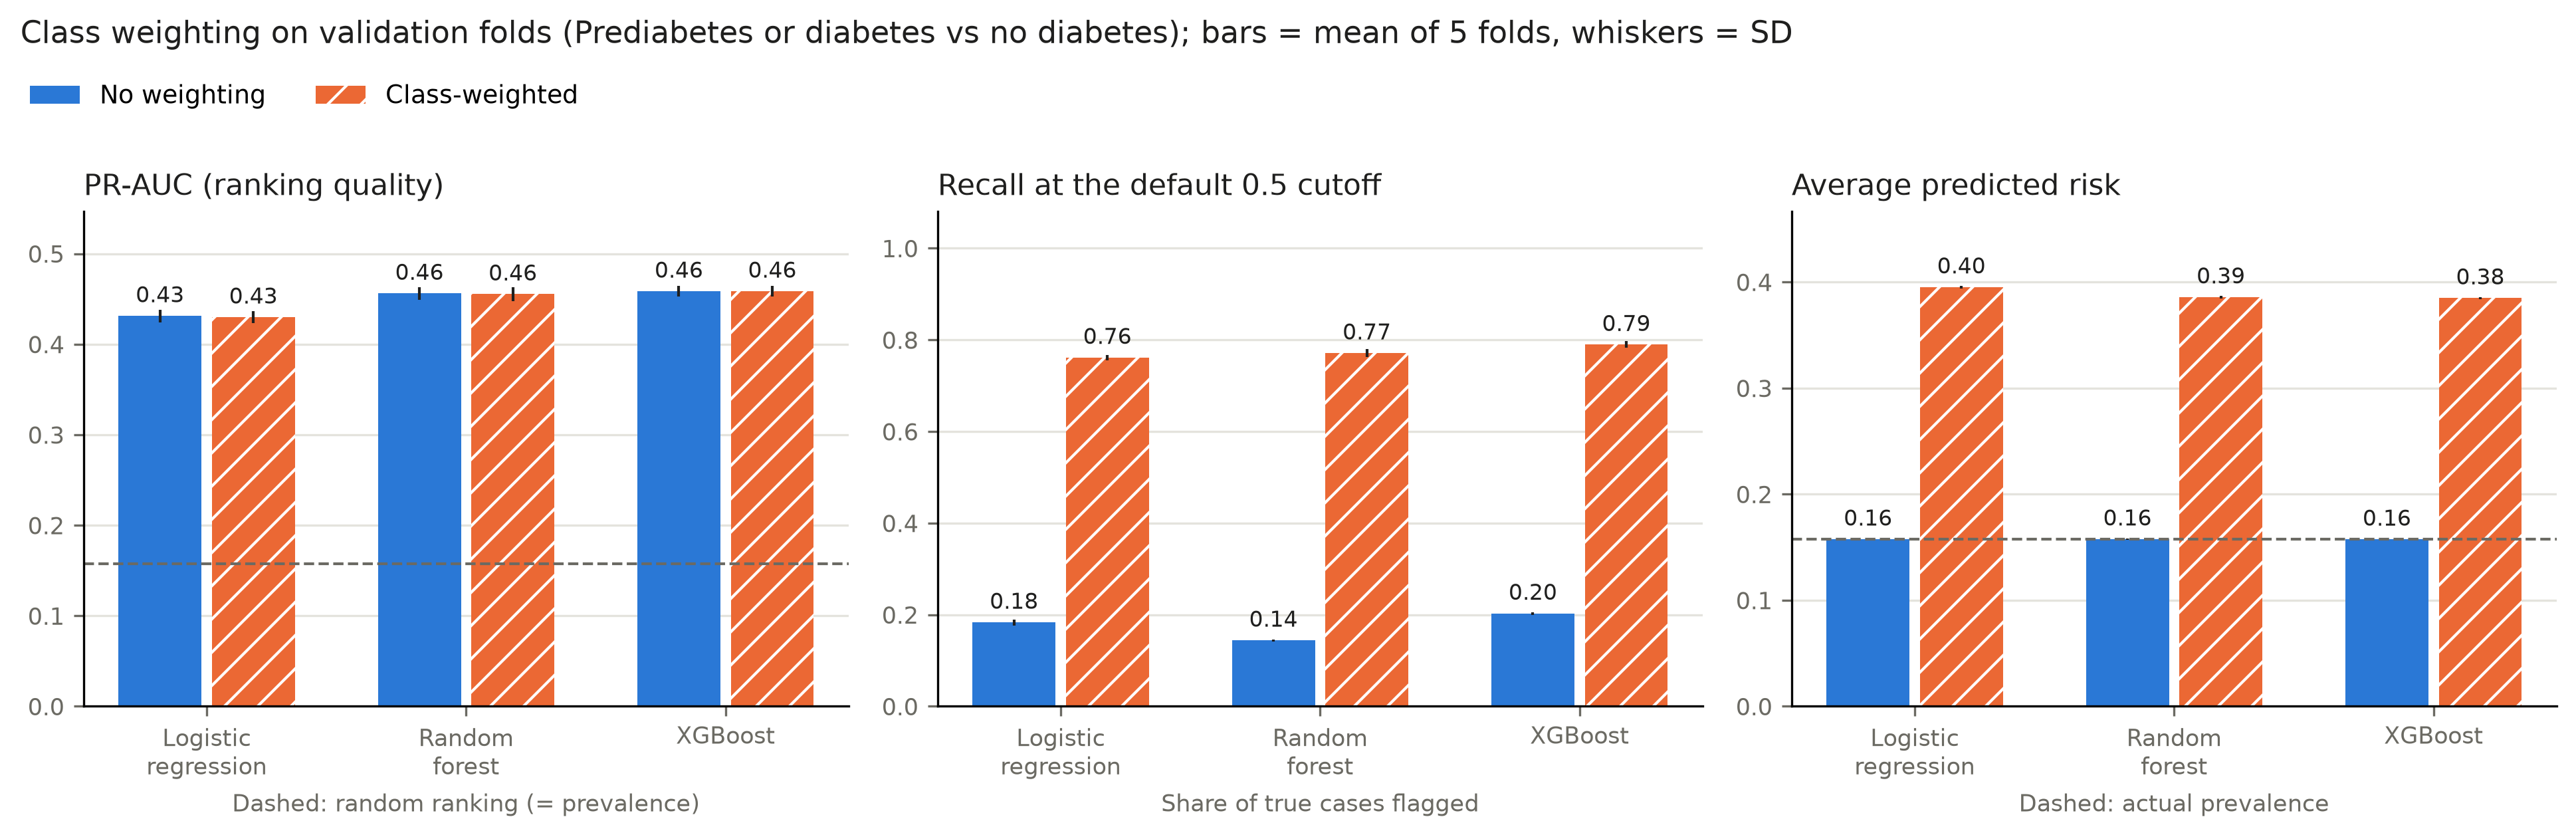

In [6]:
figure(MODELING / "imbalance" / "weighting_comparison.png")

**Takeaway.** Keeping identical profiles together changes PR-AUC by 0.001 at most, so a plain stratified split is fine. Weighting doesn't rank people any better; it only inflates predicted risks (from the true 15.8% to about 39%), which is the same as lowering the cutoff. So the models stay unweighted, their risks stay readable, and stage 7 chooses the cutoff deliberately. Write-up: [splitting](../docs/splitting.md).

This is a research prototype for risk stratification, not a diagnostic or clinical decision tool. The outcome is self-reported, the data are cross-sectional and unweighted, and associations are not causes.